In [22]:
import pandas as pd
from lmetk.case_studies.file_datamodule import CSVLongTermForecastingModule
from pathlib import Path
from omegaconf import OmegaConf
from hydra import initialize as hydra_initialize, compose
from hydra.utils import instantiate

%reload_ext autoreload
%autoreload 2
%matplotlib inline

torch.Size([32, 6, 6]) torch.Size([32, 6, 1]) torch.Size([32, 1, 6]) torch.Size([32, 1, 1])


array([[<Axes: title={'center': 'u100'}>,
        <Axes: title={'center': 'v100'}>,
        <Axes: title={'center': 'fsr'}>],
       [<Axes: title={'center': 'Windspeed'}>,
        <Axes: title={'center': 'Scaled_Windspeed_(at_123.5m)'}>,
        <Axes: title={'center': 'Wind_Direction'}>],
       [<Axes: title={'center': 'Power'}>, <Axes: >, <Axes: >]],
      dtype=object)

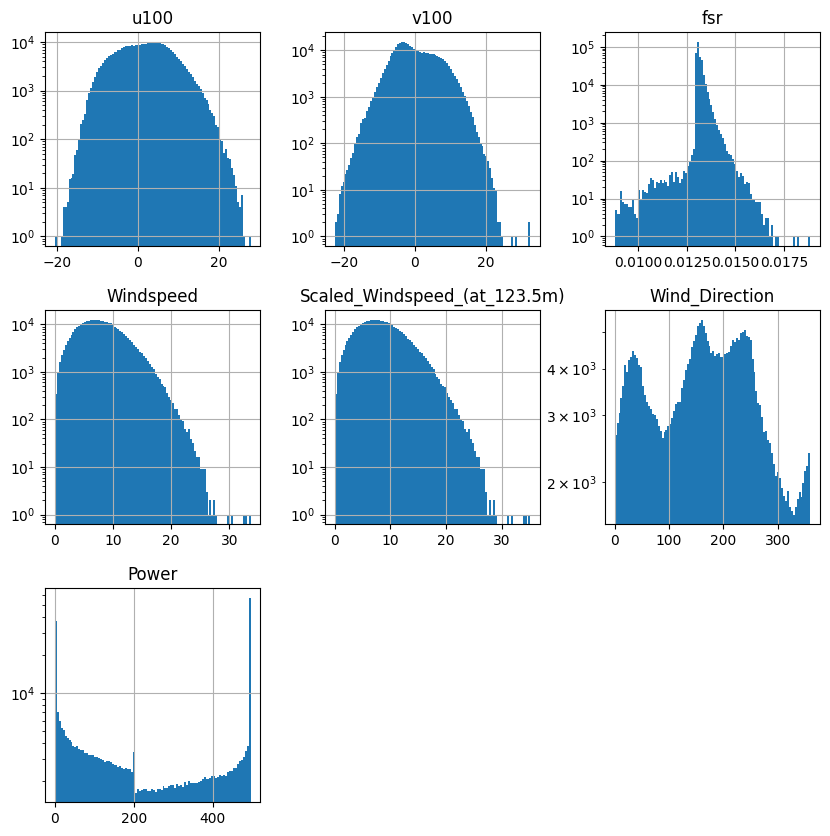

In [31]:

cfg = OmegaConf.load('configs/datamodule/wind_farm.yaml')
dm = instantiate(cfg)
dm.setup()
type(dm)
dl = dm.train_dataloader()
batch = next(iter(dl))
print(batch[0].shape, batch[1].shape, batch[2].shape, batch[3].shape)
dm.data.hist(log=True, bins=100, figsize=(10, 10))

In [ ]:

cfg = OmegaConf.load('configs/datamodule/etth1.yaml')
dm = instantiate(cfg)
dm.setup()
type(dm)
dl = dm.train_dataloader()
batch = next(iter(dl))
print(batch[0].shape, batch[1].shape, batch[2].shape, batch[3].shape)

train 8449
test 2785
val 2785
torch.Size([32, 96, 7]) torch.Size([32, 96, 7]) torch.Size([32, 96, 4]) torch.Size([32, 96, 4])


In [34]:
batch = next(iter(dm.train_dataloader()))
X, y = dm.to_sklearn(dm.train_dataloader())    

In [35]:
X.shape, y.shape

((8449, 676), (8449,))

In [36]:
batch[0].shape, batch[1].shape, batch[2].shape, batch[3].shape

(torch.Size([32, 96, 7]),
 torch.Size([32, 96, 7]),
 torch.Size([32, 96, 4]),
 torch.Size([32, 96, 4]))